# DPE Paris project: energy labels of existing dwellings
**MSA-DATI07-03 · Advanced EDA & Data Collection** · Group: Elie Maarek, Joshai Bensoussan, Lucas Noury

We collect real DPE (energy performance diagnosis) records from the ADEME API, check their quality, and prepare them for the next step of the project (predicting the DPE class of a dwelling, notebook `02_models.ipynb`).

| # | Part | Question |
|---|---|---|
| 1 | Context & provenance | Where does the data come from and for which question? |
| 2 | Parameters | Can someone else rerun the notebook and get the same result? |
| 3 | Collection & schema | Is the data collected correctly and does it match what we expect? |
| 4 | Data quality | What is missing, duplicated or odd, and what do we decide? |
| 5 | Exploration | What does the data say? Every figure has a caption. |
| 6 | Findings & next steps | What can we trust and what should we test next? |

**Deliverables:** this notebook (Restart & Run All, same fingerprint twice), `requirements.txt`, `data/raw/` (parquet + README), the data quality report (2 pages), the Git history.

---
## 1 · Context & provenance

| Field | Your answer |
|---|---|
| **Business question** | How are DPE labels (A to G) distributed in Paris, and how do they vary with construction period, surface and heating type? Later: which variables predict the DPE class of a dwelling? |
| **Source** | ADEME open-data portal (data.ademe.fr), data-fair API, dataset `dpe03existant` |
| **Dataset page / API docs** | https://data.ademe.fr/datasets/dpe03existant |
| **Collected by / when** | Elie Maarek, Joshai Bensoussan and Lucas Noury, collected on 5 November 2026 (exact time in `data/raw/README.md`) |
| **Collection method** | REST API, paginated, cached with `requests-cache` (see Section 3) |
| **Filters applied** | `code_departement_ban:"75"` (Paris), `sort=_rand` (random draw), pages of 1,000 rows, 10,000 rows maximum (`MAX_ROWS`). The dataset `dpe03existant` already excludes deactivated DPE. |
| **Licence / constraints** | Licence Ouverte 2.0 (Etalab), cite the source: ADEME |
| **Unit of observation** | One row = one DPE (identifier `numero_dpe`). It is not always a whole dwelling: `methode_application_dpe` mixes dwelling DPE, whole-building DPE and apartment DPE generated from the building DPE. One dwelling can also have had several DPE (`numero_dpe_remplace`). Checked with numbers in Section 3.3 bis. |
| **Known limitations** | 10,000 rows out of 862,377 for Paris (about 1.2 %), drawn at random at one point in time: the dataset is updated weekly, so a new collection gives other rows. A DPE is only required for a sale, a rental or a new building, so the sample does not represent all dwellings. The data is raw (typed by the diagnosticians, ADEME does not correct it). The API returns 223 columns, many almost empty. The label is computed from primary energy consumption and GHG emissions (double threshold since July 2021), so these variables must not be used to predict it. Paris only. |

---
## 2 · Setup & parameters
On Colab, run the install cell once per session. Then parameters, imports and `requirements.txt` (`pip install -r requirements.txt` to install the environment).

In [1]:
# Colab / fresh environment only
import importlib.util
missing = [p for p in ("pandera", "requests_cache") if importlib.util.find_spec(p) is None]
if missing:
    !pip install -q "pandera>=0.24" requests-cache

In [2]:
# --- Parameters: the ONLY cell you should need to edit to rerun on new data ---
SEED = 42
DATA_DIR = "../data"
REPORT_DIR = "../reports"
CACHE_HOURS = 24 * 7                              # re-use API responses for a week

BASE_URL = "https://data.ademe.fr/data-fair/api/v1/datasets/dpe03existant/lines"
QUERY = {"size": 1000, "sort": "_rand",
         "qs": 'code_departement_ban:"75"'}      # Elasticsearch-style filter; if 0 rows come back, check the field name in the API docs
MAX_ROWS = 10_000
PAUSE_S = 0.5

# cleaning thresholds
DWELLING_TYPES = ["appartement", "maison"]        # scope: dwellings, not whole buildings
DPE_START = "2021-07-01"                          # new DPE method, older rows are out of scope
SURFACE_RAW = (5, 1000)                           # m2, schema check on raw data
SURFACE_RANGE = (9, 500)                          # m2, kept after cleaning
YEAR_RANGE = (1500, 2026)                         # construction year
ENERGY_BINS = [70, 110, 180, 250, 330, 420]       # kWh/m2/year, upper limits of classes A to F
GES_BINS = [6, 11, 30, 50, 70, 100]               # kgCO2/m2/year, upper limits of classes A to F
SMALL_SURFACE = 40                                # m2, small dwellings are checked separately (label rule)
MAX_MISSING_SHARE = 0.30                          # drop a column above this share of missing values
MIN_GROUP = 50                                    # smallest group used in the MAR test and in figures
MAR_GAP = 0.10                                    # gap between groups above which missing = MAR
CONSTANT_SHARE = 0.99                             # drop a column if one value is above this share
IQR_K = 1.5
SURFACE_CLASSES = [0, 30, 60, 500]                # m2, classes used in figure 5.3
MIN_CELL = 30                                     # smallest cell shown in figure 5.3

In [3]:
import hashlib, json, random, time
from datetime import datetime, timezone
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pandera
import pandera.pandas as pa
import requests
import requests_cache
from requests.adapters import HTTPAdapter
from urllib3.util.retry import Retry

random.seed(SEED); np.random.seed(SEED)
DATA, REPORTS = Path(DATA_DIR), Path(REPORT_DIR)
for p in (DATA / "raw", DATA / "processed", REPORTS):
    p.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")

for lib in (pd, np, sns, pandera, requests):
    print(f"{lib.__name__:<10}{lib.__version__}")

pandas    3.1.1
numpy     2.5.4
seaborn   0.13.2
pandera   0.35.0
requests  2.34.2


In [4]:
# Write requirements.txt from the packages this project imports (both notebooks)
from importlib.metadata import version
pkgs = ["pandas", "numpy", "matplotlib", "seaborn", "pandera", "pyarrow", "requests", "requests-cache", "scikit-learn"]
Path("../requirements.txt").write_text("".join(f"{p}=={version(p)}\n" for p in pkgs))
print(Path("../requirements.txt").read_text())

pandas==3.1.1
numpy==2.5.4
matplotlib==3.11.2
seaborn==0.13.2
pandera==0.35.0
pyarrow==26.0.1
requests==2.34.2
requests-cache==1.3.3
scikit-learn==1.9.1



---
## 3 · Collection, ingestion & schema

### 3.1 A polite, cached HTTP session
- **Cache**: the same request is never sent twice (fast reruns, kind to the API).
- **Retry with backoff** on 429 / 5xx, respecting `Retry-After`.
- **Throttle**: pause between requests that actually hit the network.

In [5]:
session = requests_cache.CachedSession("cache/api", expire_after=CACHE_HOURS * 3600)
session.mount("https://", HTTPAdapter(max_retries=Retry(
    total=5, backoff_factor=1, status_forcelist=[429, 500, 502, 503, 504],
    respect_retry_after_header=True)))
session.headers["User-Agent"] = "MSA-DATI07-student-project/1.0"

def get(url, params=None):
    r = session.get(url, params=params, timeout=30)
    r.raise_for_status()
    if not getattr(r, "from_cache", False):
        time.sleep(PAUSE_S)
    return r

### 3.2 Collect

In [6]:
def collect_next_link(url, params, items_key, max_rows=MAX_ROWS):
    """APIs that return the URL of the next page in the response ("next").
    We follow it until it disappears or we have enough rows.
    Also returns the time of the first response (read from the cache when we rerun)."""
    rows, first, first_time = [], True, None
    while url and len(rows) < max_rows:
        r = get(url, params=params if first else None)   # the next link already contains the params
        page = r.json()
        if first:
            first_time = r.created_at.astimezone(timezone.utc).isoformat(timespec="seconds")
            total = page.get("total", page.get("count"))
            print(f"API reports {total:,} matching rows" if total is not None else "total unknown")
        rows += page.get(items_key, [])
        url, first = page.get("next"), False
    return rows[:max_rows], first_time

In [7]:
raw_rows, collected_at = collect_next_link(BASE_URL, QUERY, items_key="results")
print(f"collected {len(raw_rows):,} rows, first response at {collected_at}")

API reports 862,377 matching rows


collected 10,000 rows, first response at 2026-11-05T18:15:05+00:00


### 3.3 Flatten, save raw Parquet + README

In [8]:
df_raw = pd.json_normalize(raw_rows, sep='_')

In [9]:
raw_path = DATA / "raw" / "raw.parquet"
df_raw.to_parquet(raw_path, index=False)
(DATA / "raw" / "README.md").write_text(f"""# Raw data
- Source: ADEME open data, dataset `dpe03existant` (https://data.ademe.fr/datasets/dpe03existant), Licence Ouverte 2.0
- API: {BASE_URL}
- Collected at (UTC): {collected_at}
- Filters: `{QUERY["qs"]}` (Paris), `sort={QUERY["sort"]}` (random draw), {QUERY["size"]} rows per page, {MAX_ROWS} rows maximum
- Rows x columns: {df_raw.shape[0]} x {df_raw.shape[1]}
- Columns: {", ".join(df_raw.columns)}
""")
print(df_raw.shape)
df_raw.head()

(10000, 223)


,configuration_installation_chauffage_n1,conso_chauffage_installation_chauffage_n1,type_generateur_n1_ecs_n1,numero_voie_ban,score_ban,surface_habitable_immeuble,conso_auxiliaires_ep,deperditions_murs,cout_eclairage,conso_auxiliaires_ef,...,type_generateur_n2_installation_n2,type_energie_generateur_n2_installation_n2,conso_chauffage_generateur_n2_installation_n2,facteur_couverture_solaire_saisi_installation_chauffage_n1,type_generateur_n2_ecs_n1,volume_stockage_generateur_n2_ecs_n1,usage_generateur_n2_ecs_n1,conso_ef_generateur_n2_ecs_n1,type_energie_generateur_n2_ecs_n1,description_generateur_n2_ecs_n1
0,Installation de chauffage simple,204265.3,Chaudière gaz à condensation 2001-2015,12,0.65,4084.0,620.9,727.3,37.8,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Installation de chauffage simple,26185.0,Réseau de chaleur isolé,10,0.75,1780.0,814.4,178.8,111.9,354.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Installation de chauffage simple,2709.4,Chaudière gaz basse température 2001-2015,47,0.89,865.0,371.9,15.4,14.0,161.7,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Installation de chauffage simple,1303.8,Chaudière gaz basse température après 2015,51b,0.80,11.0,411.7,7.5,6.0,179.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Installation de chauffage simple,1.0,Ballon électrique à accumulation vertical Caté...,70,0.77,NaN,628.1,37.2,11.3,273.1,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [10]:
# First look: types, missing share, number of distinct values per column
overview = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "share_missing": df_raw.isna().mean().round(3),
    "n_unique": df_raw.nunique(dropna=True),
}).sort_values("share_missing", ascending=False)
overview

,dtype,share_missing,n_unique
description_generateur_n2_ecs_n1,str,1.0,1
usage_generateur_n2_installation_n2,str,1.0,2
_score,object,1.0,0
type_energie_generateur_n2_ecs_n1,str,1.0,1
facteur_couverture_solaire_installation_chauffage_n1,float64,1.0,2
...,...,...,...
emission_ges_5_usages,float64,0.0,8322
date_derniere_modification_dpe,str,0.0,289
etiquette_ges,str,0.0,7
_id,str,0.0,10000


### 3.3 bis · Quick checks (unit of observation)

In [11]:
# is one row one DPE, and which kinds of rows do we have?
print("numero_dpe unique:", df_raw["numero_dpe"].is_unique)
print(df_raw["methode_application_dpe"].value_counts(dropna=False))
print(df_raw["type_batiment"].value_counts(dropna=False))
print(df_raw["etiquette_dpe"].value_counts().sort_index())
print(df_raw["surface_habitable_logement"].describe())
print(df_raw["conso_5_usages_par_m2_ep"].describe())
print(df_raw["numero_dpe_remplace"].notna().sum(), "DPE replace an older DPE")

numero_dpe unique: True
methode_application_dpe
dpe appartement individuel                                                    6554
dpe appartement généré à partir des données DPE immeuble                      3219
dpe immeuble collectif                                                         167
dpe maison individuelle                                                         54
dpe issu d'une étude thermique réglementaire RT2012 bâtiment : appartement       6
Name: count, dtype: int64
type_batiment
appartement    9779
immeuble        167
maison           54
Name: count, dtype: int64
etiquette_dpe
A      12
B     117
C    2208
D    3067
E    2789
F    1111
G     696
Name: count, dtype: int64
count    9833.000000
mean       51.274453
std        54.045073
min         3.000000
25%        28.100000
50%        44.100000
75%        65.000000
max      3450.000000
Name: surface_habitable_logement, dtype: float64
count    10000.000000
mean       266.130500
std        127.137725
min          2.800

### 3.4 Schema-as-contract

We keep **20 columns out of 223**: most of the others are almost empty or useless for the question. They fall into three groups:
- **Identifiers / DPE type**: `numero_dpe`, `numero_dpe_remplace`, `date_etablissement_dpe`, `methode_application_dpe`, `type_batiment`.
- **Target and the columns that compute it**: `etiquette_dpe` is the target. `etiquette_ges`, `conso_5_usages_par_m2_ep` and `emission_ges_5_usages_par_m2` compute the letter (it is the worse of the energy and GHG classes). We keep them to check the data but never use them in a model (target leakage).
- **Dwelling descriptors** (surface, construction period, heating, climate zone, address) and **intermediate variables** (heat losses, ubat, insulation quality).

The contract is validated on the raw data with `lazy=True`: all errors come back at once, and the summary is saved in `reports/schema_failures.csv` for the report.

In [12]:
KEEP = [
    # identifiers and DPE type
    "numero_dpe", "numero_dpe_remplace", "date_etablissement_dpe",
    "methode_application_dpe", "type_batiment",
    # target + the columns that compute it (leakage: not in the model)
    "etiquette_dpe", "etiquette_ges",
    "conso_5_usages_par_m2_ep", "emission_ges_5_usages_par_m2",
    # dwelling descriptors
    "surface_habitable_logement", "periode_construction", "annee_construction",
    "type_energie_principale_chauffage", "type_installation_chauffage",
    "zone_climatique", "code_postal_ban", "identifiant_ban",
    # computed intermediate variables
    "deperditions_enveloppe", "ubat_w_par_m2_k", "qualite_isolation_enveloppe",
]
df_sel = df_raw[KEEP].copy()

LETTERS = list("ABCDEFG")

schema = pa.DataFrameSchema({
    # one DPE = one number, always present and unique
    "numero_dpe": pa.Column("string", unique=True, coerce=True),
    # nullable: only filled when the DPE replaces an older one
    "numero_dpe_remplace": pa.Column("string", nullable=True, coerce=True),
    "date_etablissement_dpe": pa.Column("string", coerce=True, checks=[
        pa.Check.str_matches(r"^\d{4}-\d{2}-\d{2}"),
        pa.Check(lambda s: s >= DPE_START, error=f"before {DPE_START}"),
    ]),
    "methode_application_dpe": pa.Column("string", coerce=True),
    "type_batiment": pa.Column("string", coerce=True,
                               checks=pa.Check.isin(DWELLING_TYPES + ["immeuble"])),
    "etiquette_dpe": pa.Column("string", coerce=True, checks=pa.Check.isin(LETTERS)),
    "etiquette_ges": pa.Column("string", coerce=True, checks=pa.Check.isin(LETTERS)),
    "conso_5_usages_par_m2_ep": pa.Column(float, coerce=True, checks=pa.Check.gt(0)),
    "emission_ges_5_usages_par_m2": pa.Column(float, coerce=True, checks=pa.Check.ge(0)),
    # nullable: the surface is empty for whole-building DPE (see 4.3)
    "surface_habitable_logement": pa.Column(float, nullable=True, coerce=True,
                                            checks=pa.Check.in_range(*SURFACE_RAW)),
    "periode_construction": pa.Column("string", nullable=True, coerce=True),
    # nullable: about 50 % empty in the raw data, tested in 4.3
    "annee_construction": pa.Column(float, nullable=True, coerce=True,
                                    checks=pa.Check.in_range(*YEAR_RANGE)),
    # the next columns are almost always filled; nullable only for the few missing values counted in 4.3
    "type_energie_principale_chauffage": pa.Column("string", nullable=True, coerce=True),
    "type_installation_chauffage": pa.Column("string", nullable=True, coerce=True),    # 0.5 % empty
    "zone_climatique": pa.Column("string", nullable=True, coerce=True),               # 0.2 % empty
    "code_postal_ban": pa.Column("string", nullable=True, coerce=True),
    "identifiant_ban": pa.Column("string", nullable=True, coerce=True),
    "deperditions_enveloppe": pa.Column(float, nullable=True, coerce=True, checks=pa.Check.ge(0)),   # 0.2 % empty
    "ubat_w_par_m2_k": pa.Column(float, nullable=True, coerce=True, checks=pa.Check.ge(0)),
    "qualite_isolation_enveloppe": pa.Column("string", nullable=True, coerce=True),
}, strict=True)

try:
    schema.validate(df_sel, lazy=True)
    print("✅ raw data passes the contract")
except pa.errors.SchemaErrors as err:
    fails = err.failure_cases
    print(f"❌ {len(fails)} violations")
    schema_summary = fails.groupby(["column", "check"]).size().rename("n").reset_index()
    schema_summary.to_csv(REPORTS / "schema_failures.csv", index=False)
    display(schema_summary)

❌ 3 violations


,column,check,n
0,surface_habitable_logement,"in_range(5, 1000)",3


---
## 4 · Data quality
Measure, decide, note: every decision goes through `log(...)` and the final table goes into the report.

In [13]:
decisions = []
dropped = []
def log(column, issue, n_rows, decision, why):
    decisions.append(dict(column=column, issue=issue, n_rows=n_rows, decision=decision, why=why))

df = df_sel.copy()

log("(all columns)", "223 columns, many almost empty or off-topic", len(df_raw),
    "keep 20 columns (KEEP)",
    "target + descriptors + intermediate variables useful for the question; the columns that compute the label are kept for checks but not for the model")

### 4.1 Scope and duplicates

In [14]:
# scope: dwellings, not whole-building DPE
n_imm = int((~df["type_batiment"].isin(DWELLING_TYPES)).sum())
df = df[df["type_batiment"].isin(DWELLING_TYPES)].copy()
log("type_batiment", "whole-building DPE, not a dwelling", n_imm,
    "rows removed", "we study dwellings, and the dwelling surface is empty for these rows")

# apartments whose DPE is generated from the building DPE
df["dpe_immeuble_genere"] = df["methode_application_dpe"].str.contains("généré", na=False)
n_gen = int(df["dpe_immeuble_genere"].sum())
log("methode_application_dpe", "apartment DPE generated from the building DPE", n_gen,
    "kept + column dpe_immeuble_genere",
    "the result comes from the building: neighbours look alike, so train/test must be split by building")

# exact duplicates
dups = df.astype(str).duplicated()
n_exact = int(dups.sum())
df = df[~dups]
log("(all columns)", "identical rows", n_exact, "rows removed" if n_exact else "nothing to do",
    "checked on the kept columns")
print("buildings removed:", n_imm, "· DPE generated from the building:", n_gen, "· exact duplicates:", n_exact)

buildings removed: 167 · DPE generated from the building: 3219 · exact duplicates: 0


In [15]:
# a DPE can replace an older one: we keep the most recent
old = df["numero_dpe"].isin(df["numero_dpe_remplace"].dropna())
print(int(df["numero_dpe_remplace"].notna().sum()), "DPE replace another one ·",
      int(old.sum()), "old DPE still present")
log("numero_dpe_remplace", "old DPE still present next to its replacement", int(old.sum()),
    "old DPE removed" if old.any() else "nothing to do", "we keep the most recent diagnosis")
df = df[~old]

1121 DPE replace another one · 0 old DPE still present


In [16]:
# near-identical dwellings in the same building
keys = ["identifiant_ban", "surface_habitable_logement", "periode_construction",
        "type_energie_principale_chauffage", "etiquette_dpe"]
near = df.duplicated(subset=keys, keep=False) & df["identifiant_ban"].notna()
print(int(near.sum()), "near-identical rows, of which", f"{df.loc[near, 'dpe_immeuble_genere'].mean():.0%}", "generated DPE")
log("identifiant_ban", "near-identical dwellings in the same building", int(near.sum()),
    "kept", "often really different dwellings; mainly we avoid splitting them between train and test")

429 near-identical rows, of which 96% generated DPE


### 4.2 Impossible values

In [17]:
# numeric columns as real numbers
nums = ["conso_5_usages_par_m2_ep", "emission_ges_5_usages_par_m2", "surface_habitable_logement",
        "annee_construction", "deperditions_enveloppe", "ubat_w_par_m2_k"]
df[nums] = df[nums].apply(pd.to_numeric, errors="coerce")
display(df[nums].describe().T)

# empty surface, or outside the allowed range: not a normal dwelling
out_surface = ~df["surface_habitable_logement"].between(*SURFACE_RANGE)
print(int(df["surface_habitable_logement"].isna().sum()), "empty surfaces ·", int(out_surface.sum()),
      f"rows outside {SURFACE_RANGE[0]}-{SURFACE_RANGE[1]} m²")
if out_surface.any():
    log("surface_habitable_logement", f"surface empty or outside {SURFACE_RANGE[0]}-{SURFACE_RANGE[1]} m²", int(out_surface.sum()),
        "rows removed", "impossible for a dwelling, and the surface is used almost everywhere")
df = df[~out_surface]

# impossible construction year
bad_year = ~df["annee_construction"].between(*YEAR_RANGE) & df["annee_construction"].notna()
df.loc[bad_year, "annee_construction"] = np.nan
if bad_year.any():
    log("annee_construction", f"year outside {YEAR_RANGE[0]}-{YEAR_RANGE[1]}", int(bad_year.sum()),
        "set to missing", "we keep the rest of the row")

# negative values
for col in ["deperditions_enveloppe", "ubat_w_par_m2_k"]:
    neg = df[col] < 0
    df.loc[neg, col] = np.nan
    if neg.any():
        log(col, "negative value", int(neg.sum()), "set to missing", "heat loss cannot be negative")

# DPE before the new method: out of scope
too_old = df["date_etablissement_dpe"] < DPE_START
if too_old.any():
    log("date_etablissement_dpe", f"DPE before {DPE_START}", int(too_old.sum()),
        "rows removed", "old calculation method")
df = df[~too_old]
print(len(df), "rows left")

,count,mean,std,min,25%,50%,75%,max
conso_5_usages_par_m2_ep,9833.0,266.220391,127.132728,37.40,182.00,245.00,317.40,1333.60
emission_ges_5_usages_par_m2,9833.0,32.077159,25.814978,0.10,11.00,25.00,47.80,295.00
surface_habitable_logement,9832.0,50.928773,41.785842,3.00,28.10,44.10,65.00,2464.00
annee_construction,4883.0,1948.824084,40.783990,1600.00,1930.00,1948.00,1977.00,2025.00
deperditions_enveloppe,9810.0,4398.632844,10538.015824,7.90,86.00,170.50,3350.60,92456.10
ubat_w_par_m2_k,9833.0,1.510802,0.840931,0.05,0.82,1.38,2.12,6.57


1 empty surfaces · 79 rows outside 9-500 m²
9754 rows left


In [18]:
# the label must be the worse of the energy class and the GHG class
letters = np.array(LETTERS)
c_ep = pd.cut(df["conso_5_usages_par_m2_ep"], [-np.inf] + ENERGY_BINS + [np.inf], labels=False)
c_ges = pd.cut(df["emission_ges_5_usages_par_m2"], [-np.inf] + GES_BINS + [np.inf], labels=False)
recomputed = pd.Series(letters[np.fmax(c_ep, c_ges).fillna(6).astype(int)], index=df.index)
mismatch = (recomputed != df["etiquette_dpe"].astype(str)) & c_ep.notna() & c_ges.notna()
small = df["surface_habitable_logement"] < SMALL_SURFACE
gap_small, gap_large = mismatch[small].mean(), mismatch[~small].mean()
favourable = (recomputed[mismatch] > df.loc[mismatch, "etiquette_dpe"].astype(str)).mean()
print(f"{mismatch.mean():.1%} of labels differ: {gap_small:.1%} under {SMALL_SURFACE} m², {gap_large:.1%} above")
print(f"in {favourable:.0%} of cases the label is better than the recomputed one")
log("etiquette_dpe", "label different from the one recomputed with consumption and GHG", int(mismatch.sum()),
    "rows kept",
    f"gap mostly under {SMALL_SURFACE} m² ({gap_small:.0%} vs {gap_large:.0%}) and in the favourable direction: probably the small-surface rule; these columns compute the label, so not in the model")

14.3% of labels differ: 30.1% under 40 m², 2.2% above
in 91% of cases the label is better than the recomputed one


### 4.3 Missing values: understand before filling

In [19]:
miss = df.isna().mean().sort_values(ascending=False)
miss = miss[miss > 0].rename("share_missing").to_frame()
miss["flag"] = np.where(miss.share_missing > MAX_MISSING_SHARE, "⚠️ high", "")
miss

,share_missing,flag
numero_dpe_remplace,0.885893,⚠️ high
annee_construction,0.502255,⚠️ high
type_installation_chauffage,0.005434,
deperditions_enveloppe,0.002358,
zone_climatique,0.002153,
identifiant_ban,0.000205,


In [20]:
# does the missingness depend on the DPE type? (MAR test)
if "numero_dpe_remplace" in miss.index:
    log("numero_dpe_remplace", "empty when the DPE replaces nothing", int(df["numero_dpe_remplace"].isna().sum()),
        "kept as is", "structural missing, not an error")

for col in [c for c in miss.index if c != "numero_dpe_remplace"][:3]:
    share = df[col].isna().mean()
    g = df.assign(m=df[col].isna()).groupby("methode_application_dpe")["m"].agg(["mean", "size"])
    g = g[g["size"] >= MIN_GROUP]
    gap = g["mean"].max() - g["mean"].min() if len(g) > 1 else 0
    mech = "MAR (depends on the DPE type)" if gap > MAR_GAP else "probably MCAR"
    print(f"{col}: {share:.1%} missing, gap between DPE types {gap:.1%} -> {mech}")
    n_empty = int(df[col].isna().sum())
    if share > MAX_MISSING_SHARE:
        df = df.drop(columns=col)
        dropped.append(col)
        log(col, f"{share:.0%} missing, {mech}", n_empty, "column dropped", f"more than {MAX_MISSING_SHARE:.0%} empty")
    else:
        log(col, f"{share:.1%} missing, {mech}", n_empty, "kept, to impute later",
            "imputed in the model pipeline, with train statistics only")

annee_construction: 50.2% missing, gap between DPE types 46.2% -> MAR (depends on the DPE type)
type_installation_chauffage: 0.5% missing, gap between DPE types 100.0% -> MAR (depends on the DPE type)
deperditions_enveloppe: 0.2% missing, gap between DPE types 13.2% -> MAR (depends on the DPE type)


In [21]:
# almost constant columns learn nothing
to_check = ["zone_climatique", "type_installation_chauffage", "type_energie_principale_chauffage",
            "periode_construction", "qualite_isolation_enveloppe", "code_postal_ban"]
for col in [c for c in to_check if c in df.columns]:
    top = df[col].value_counts(normalize=True).iloc[0]
    if top > CONSTANT_SHARE:
        n_other = int((df[col] != df[col].value_counts().index[0]).sum())
        df = df.drop(columns=col)
        dropped.append(col)
        log(col, f"{top:.1%} of rows have the same value", n_other, "column dropped", "almost constant, useless to explain the label")
        print(col, "dropped:", f"{top:.1%}", "identical")

zone_climatique dropped: 99.7% identical


### 4.4 Extreme values: sort them, do not delete them

In [22]:
# key variable: consumption per m² (very skewed, so log scale)
col = "conso_5_usages_par_m2_ep"
x = np.log1p(df[col])
q1, q3 = x.quantile([0.25, 0.75])
low, high = q1 - IQR_K * (q3 - q1), q3 + IQR_K * (q3 - q1)
df["conso_outlier"] = (x < low) | (x > high)
n_out = int(df["conso_outlier"].sum())
n_high, n_low = int((x > high).sum()), int((x < low).sum())
print(n_out, "extreme values, limits:", round(np.expm1(low), 1), "and", round(np.expm1(high), 1), "kWh/m²/year")
print(pd.crosstab(np.where(x > high, "very high", "very low")[df["conso_outlier"]],
                  df.loc[df["conso_outlier"], "etiquette_dpe"]))

# error or real extreme? look at the rows behind the flag
print("median surface of all dwellings:", df["surface_habitable_logement"].median(), "m²")
for name, mask in [("very high", x > high), ("very low", x < low)]:
    g = df[mask]
    print(f"{name}: min {g[col].min():.0f}, max {g[col].max():.0f} kWh/m²/year · median surface {g['surface_habitable_logement'].median():.0f} m²"
          f" · label equal to the GHG label in {(g['etiquette_dpe'] == g['etiquette_ges']).mean():.0%} of rows")
extremes = df[df["conso_outlier"]].sort_values(col)       # 3 lowest and 3 highest rows
display(extremes.iloc[[0, 1, 2, -3, -2, -1]][[col, "emission_ges_5_usages_par_m2", "surface_habitable_logement",
                                              "etiquette_dpe", "etiquette_ges"]])
log(col, "extreme values (IQR on log scale)", n_out, "kept + column conso_outlier",
    f"{n_high} very high (label G, small dwellings: real extremes) and {n_low} very low (almost all A to C, the GHG class decides the label): consistent, not errors, so not deleted")

158 extreme values, limits: 78.4 and 726.5 kWh/m²/year
etiquette_dpe  A   B   C  E   G
row_0                          
very high      0   0   0  0  80
very low       8  33  36  1   0
median surface of all dwellings: 44.45 m²
very high: min 727, max 1334 kWh/m²/year · median surface 17 m² · label equal to the GHG label in 30% of rows
very low: min 37, max 78 kWh/m²/year · median surface 67 m² · label equal to the GHG label in 92% of rows


,conso_5_usages_par_m2_ep,emission_ges_5_usages_par_m2,surface_habitable_logement,etiquette_dpe,etiquette_ges
601,37.4,1.1,54.1,C,A
1288,44.5,1.0,42.6,A,A
9693,58.0,9.0,38.4,E,B
2917,1090.5,243.0,68.0,G,G
9481,1214.4,169.0,9.2,G,G
4021,1333.6,279.4,26.0,G,G


In [23]:
decision_table = pd.DataFrame(decisions, columns=["column", "issue", "n_rows", "decision", "why"])
decision_table.to_csv(REPORTS / "decision_table.csv", index=False)
decision_table

,column,issue,n_rows,decision,why
0,(all columns),"223 columns, many almost empty or off-topic",10000,keep 20 columns (KEEP),target + descriptors + intermediate variables ...
1,type_batiment,"whole-building DPE, not a dwelling",167,rows removed,"we study dwellings, and the dwelling surface i..."
2,methode_application_dpe,apartment DPE generated from the building DPE,3219,kept + column dpe_immeuble_genere,the result comes from the building: neighbours...
3,(all columns),identical rows,0,nothing to do,checked on the kept columns
4,numero_dpe_remplace,old DPE still present next to its replacement,0,nothing to do,we keep the most recent diagnosis
5,identifiant_ban,near-identical dwellings in the same building,429,kept,often really different dwellings; mainly we av...
6,surface_habitable_logement,surface empty or outside 9-500 m²,79,rows removed,"impossible for a dwelling, and the surface is ..."
7,etiquette_dpe,label different from the one recomputed with c...,1398,rows kept,gap mostly under 40 m² (30% vs 2%) and in the ...
8,numero_dpe_remplace,empty when the DPE replaces nothing,8641,kept as is,"structural missing, not an error"
9,annee_construction,"50% missing, MAR (depends on the DPE type)",4899,column dropped,more than 30% empty


---
## 5 · Exploration
Every figure has a title that says what we see, a caption and a "so what?".

In [24]:
def show(fig, title, caption, so_what, name):
    fig.suptitle(title, x=0.01, ha="left", fontsize=12, fontweight="bold")
    fig.tight_layout(rect=(0, 0, 1, 0.94))
    fig.text(0.01, -0.04, f"{caption}\n→ {so_what}", ha="left", va="top", fontsize=9, wrap=True)
    fig.savefig(REPORTS / f"{name}.png", bbox_inches="tight", dpi=120)
    plt.show()

clean = df.reset_index(drop=True)

### 5.1 One variable: consumption

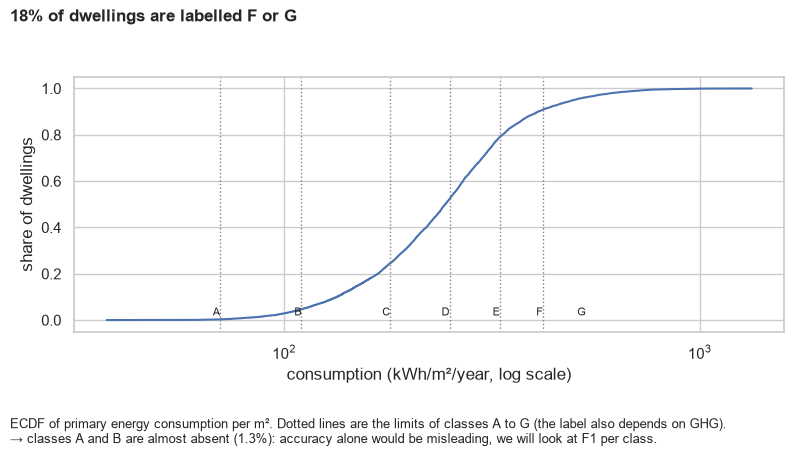

In [25]:
dfe = clean.assign(fg=clean["etiquette_dpe"].isin(["F", "G"]))
share_fg = dfe["fg"].mean()
share_ab = dfe["etiquette_dpe"].isin(["A", "B"]).mean()

x = np.sort(dfe["conso_5_usages_par_m2_ep"])
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(x, np.arange(1, len(x) + 1) / len(x))
for limit, letter in zip(ENERGY_BINS, "ABCDEF"):
    ax.axvline(limit, color="grey", ls=":", lw=1)
    ax.text(limit, 0.02, letter, ha="right", fontsize=8)
ax.text(520, 0.02, "G", ha="center", fontsize=8)
ax.set_xscale("log")
ax.set_xlabel("consumption (kWh/m²/year, log scale)")
ax.set_ylabel("share of dwellings")
show(fig, f"{share_fg:.0%} of dwellings are labelled F or G",
     "ECDF of primary energy consumption per m². Dotted lines are the limits of classes A to G (the label also depends on GHG).",
     f"classes A and B are almost absent ({share_ab:.1%}): accuracy alone would be misleading, we will look at F1 per class.",
     "5_1")

### 5.2 Two variables: period and heating

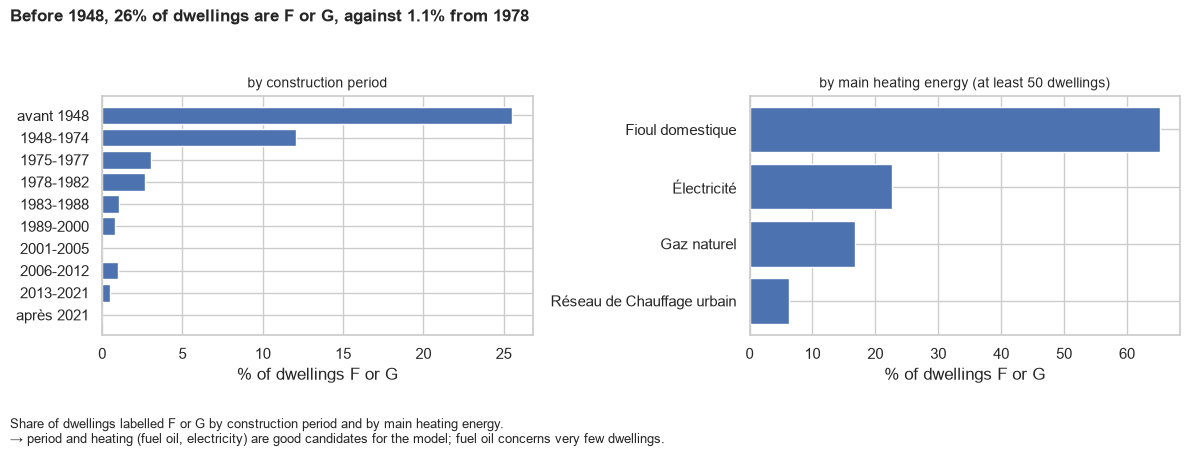

In [26]:
def order(p):
    if p.startswith("avant"):
        return 0
    if p.startswith("après"):
        return 9999
    return int(p[:4])

periods = sorted(dfe["periode_construction"].unique(), key=order)
by_period = dfe.groupby("periode_construction")["fg"].mean().reindex(periods)
recent = dfe.loc[dfe["periode_construction"].map(order) >= 1978, "fg"].mean()

heating = dfe.groupby("type_energie_principale_chauffage")["fg"].agg(["mean", "size"])
heating = heating[heating["size"] >= MIN_GROUP].sort_values("mean")

fig, (a1, a2) = plt.subplots(1, 2, figsize=(12, 4))
a1.barh(periods, by_period * 100)
a1.invert_yaxis()
a1.set_title("by construction period", fontsize=10)
a1.set_xlabel("% of dwellings F or G")
a2.barh(heating.index, heating["mean"] * 100)
a2.set_title(f"by main heating energy (at least {MIN_GROUP} dwellings)", fontsize=10)
a2.set_xlabel("% of dwellings F or G")
show(fig, f"Before 1948, {by_period[periods[0]]:.0%} of dwellings are F or G, against {recent:.1%} from 1978",
     "Share of dwellings labelled F or G by construction period and by main heating energy.",
     "period and heating (fuel oil, electricity) are good candidates for the model; fuel oil concerns very few dwellings.",
     "5_2")

### 5.3 Three variables: period, surface and label

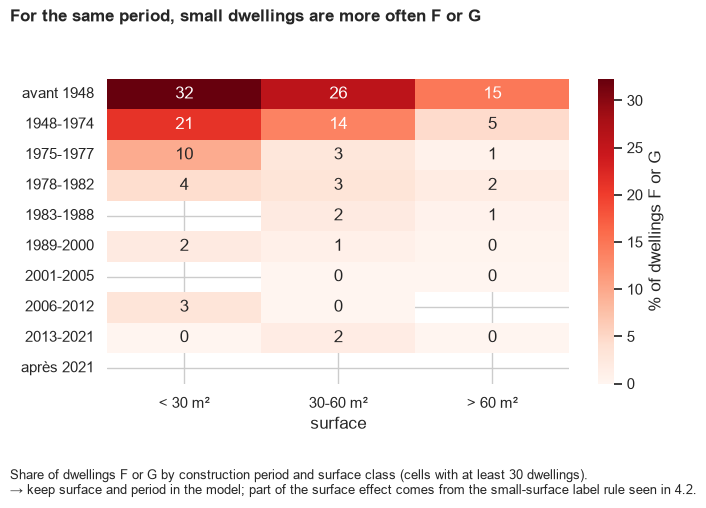

In [27]:
dfe["surface_class"] = pd.cut(dfe["surface_habitable_logement"], SURFACE_CLASSES,
                             labels=["< 30 m²", "30-60 m²", "> 60 m²"])
tab = dfe.pivot_table(index="periode_construction", columns="surface_class", values="fg",
                      aggfunc="mean", observed=True).reindex(periods)
size = dfe.pivot_table(index="periode_construction", columns="surface_class", values="fg",
                       aggfunc="size", observed=True).reindex(periods)
tab = tab.where(size >= MIN_CELL) * 100

fig, ax = plt.subplots(figsize=(7, 4.5))
sns.heatmap(tab, annot=True, fmt=".0f", cmap="Reds", cbar_kws={"label": "% of dwellings F or G"}, ax=ax)
ax.set_xlabel("surface")
ax.set_ylabel("")
show(fig, "For the same period, small dwellings are more often F or G",
     f"Share of dwellings F or G by construction period and surface class (cells with at least {MIN_CELL} dwellings).",
     "keep surface and period in the model; part of the surface effect comes from the small-surface label rule seen in 4.2.",
     "5_3")

### 5.4 Numbers quoted in Section 6

In [28]:
by_insulation = dfe.groupby("qualite_isolation_enveloppe")["fg"].agg(["mean", "size"])
by_generated = dfe.groupby("dpe_immeuble_genere")["fg"].agg(["mean", "size"])
print("% F or G by period:\n", (by_period * 100).round(1).to_string(), sep="")
print("\n% F or G by insulation quality:\n", by_insulation.assign(mean=(by_insulation["mean"] * 100).round(1)).to_string(), sep="")
print("\n% F or G, DPE generated from the building (True) or not:\n",
      by_generated.assign(mean=(by_generated["mean"] * 100).round(1)).to_string(), sep="")
print(f"\nshare of generated DPE: {dfe['dpe_immeuble_genere'].mean():.0%}")

% F or G by period:
periode_construction
avant 1948    25.5
1948-1974     12.0
1975-1977      3.1
1978-1982      2.7
1983-1988      1.0
1989-2000      0.8
2001-2005      0.0
2006-2012      1.0
2013-2021      0.5
après 2021     0.0

% F or G by insulation quality:
                             mean  size
qualite_isolation_enveloppe            
bonne                         3.8   897
insuffisante                 22.4  7154
moyenne                       8.8  1022
très bonne                    1.8   681

% F or G, DPE generated from the building (True) or not:
                     mean  size
dpe_immeuble_genere            
False                23.7  6538
True                  5.8  3216

share of generated DPE: 33%


---
## 6 · Findings, what cannot be trusted, next steps

**Three findings**
1. **About 18 % of dwellings are F or G** and classes A and B are barely 1 % (figure 5.1). The classes are very unbalanced: we will follow F1 per class, not only accuracy.
2. **The age of the building is the clearest variable** (figure 5.2): 26 % F or G before 1948, 12 % between 1948 and 1974, about 1 % from 1978. Heating also matters (fuel oil 65 %, electricity 23 %, gas 17 %, district heating 6 %).
3. **For the same period, small dwellings are more often F or G** (figure 5.3): before 1948, 32 % under 30 m² against 15 % above 60 m².

The exact numbers are printed in 5.4.

**What cannot be trusted** (column, subset, why)
- `conso_5_usages_par_m2_ep`, `emission_ges_5_usages_par_m2` and `etiquette_ges` compute the label: they must be left out of the model. For dwellings under 40 m², the label does not always match the calculation (30 % mismatch against 2 % above).
- A third of the dwellings are DPE generated from the building DPE: neighbours look alike and these are rarely F or G (6 % against 24 %). Train and test must be split by building (`identifiant_ban`), and results on this sample should be taken carefully.
- Small groups (LPG, wood, coal, period "après 2021", class A) have too few rows to conclude.
- 10,000 random dwellings out of 862,377 in Paris, and a DPE is only made for a sale, a rental or a new building: we cannot generalise to all dwellings.

**Five testable hypotheses** (variable, direction, population, test)
- **H1:** `periode_construction`, before 1948 gives more F or G than from 1978. Population: the 9,754 cleaned dwellings. Test: chi-square.
- **H2:** `surface_habitable_logement`, for the same period, the smaller the dwelling, the more F or G. Population: all dwellings. Test: logistic regression (period, surface).
- **H3:** `type_energie_principale_chauffage`, fuel oil and electricity give more F or G than gas and district heating. Population: groups of at least 50 dwellings (fuel oil has 89). Test: chi-square, then Kruskal-Wallis on consumption.
- **H4:** `qualite_isolation_enveloppe`, "insuffisante" gives more F or G than "bonne" (22 % against less than 4 %). Population: all dwellings. Test: chi-square. Insulation is computed from the building, so part of the link is by construction.
- **H5:** `dpe_immeuble_genere`, generated DPE are less often F or G, and the gap comes from the building type and not from the calculation. Population: all dwellings, at equal period and heating. Test: stratified comparison.

### Final contract and fingerprint
Contract on the clean data, then Restart & Run All twice: the fingerprint must be identical.

In [29]:
clean_schema = (schema
    .remove_columns(dropped)
    .add_columns({"dpe_immeuble_genere": pa.Column(bool), "conso_outlier": pa.Column(bool)})
    .update_column("type_batiment", checks=pa.Check.isin(DWELLING_TYPES))
    .update_column("surface_habitable_logement", nullable=False, checks=pa.Check.in_range(*SURFACE_RANGE)))
clean = clean_schema.validate(clean, lazy=True)
print("✅ clean data passes the contract")

clean.to_parquet(DATA / "processed" / "clean.parquet", index=False)
fingerprint = hashlib.sha256(
    pd.util.hash_pandas_object(clean.astype(str), index=False).values.tobytes()).hexdigest()[:12]
print("rows:", len(clean), "· fingerprint:", fingerprint)

✅ clean data passes the contract
rows: 9754 · fingerprint: 78abd427b5da


> **Reproducibility note.** The fingerprint is stable between runs *thanks to the cache*: the API data changes over time, so a run without the cache (or after `CACHE_HOURS`) can give a different fingerprint. That is expected. The collection date is in Section 1 and in `data/raw/README.md`, and the raw Parquet is committed.